# Лабораторна робота №3: Model Development (Розробка моделей передбачення)

**Мета роботи:** отримати навички розробки моделей для передбачення (проста лінійна регресія, множинна лінійна регресія, поліноміальна регресія, конвеєри `Pipeline` та оцінка точності за допомогою $R^2$ і $\text{MSE}$).

---

## 1. Імпорт бібліотек та завантаження підготовлених даних

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score
%matplotlib inline

# Завантаження очищеного датасету
if os.path.exists("clean_auto.csv"):
    df = pd.read_csv("clean_auto.csv")
else:
    headers = [
        "symboling", "normalized-losses", "make", "fuel-type", "aspiration",
        "num-of-doors", "body-style", "drive-wheels", "engine-location", "wheel-base",
        "length", "width", "height", "curb-weight", "engine-type",
        "num-of-cylinders", "engine-size", "fuel-system", "bore", "stroke",
        "compression-ratio", "horsepower", "peak-rpm", "city-mpg", "highway-mpg", "price"
    ]
    df = pd.read_csv("auto.csv", names=headers).replace("?", np.nan)
    df.dropna(subset=["price"], axis=0, inplace=True)
    for col in ["normalized-losses", "bore", "stroke", "horsepower", "peak-rpm", "price"]:
        df[col] = df[col].astype("float")
        df[col] = df[col].fillna(df[col].mean())

print(f"Форма датасету: {df.shape}")
df[["highway-mpg", "engine-size", "horsepower", "curb-weight", "normalized-losses", "price"]].head()

Форма датасету: (201, 26)


,highway-mpg,engine-size,horsepower,curb-weight,normalized-losses,price
0,27,130,111,2548,122,13495.0
1,27,130,111,2548,122,16500.0
2,26,152,154,2823,122,16500.0
3,30,109,102,2337,164,13950.0
4,22,136,115,2824,164,17450.0


---

## 2. Проста лінійна регресія (Simple Linear Regression — SLR) та Завдання 1

Проста лінійна регресія моделює залежність між однією незалежною змінною $X$ і залежною змінною $Y$:
$$\hat{Y} = b_0 + b_1 X$$

Спочатку розглянемо базовий приклад із методичних вказівок (`highway-mpg` $\rightarrow$ `price`), включаючи графік регресії та графік залишків.

In [2]:
lm_hwy = LinearRegression()
X_hwy = df[["highway-mpg"]]
Y = df["price"]
lm_hwy.fit(X_hwy, Y)

Yhat_hwy = lm_hwy.predict(X_hwy)
r2_hwy = lm_hwy.score(X_hwy, Y)
mse_hwy = mean_squared_error(Y, Yhat_hwy)

print(f"Модель SLR (highway-mpg -> price):")
print(f"  Intercept (b0): {lm_hwy.intercept_:.2f}")
print(f"  Slope (b1):     {lm_hwy.coef_[0]:.2f}")
print(f"  Рівняння:       price = {lm_hwy.intercept_:.2f} + ({lm_hwy.coef_[0]:.2f}) * highway-mpg")
print(f"  R^2:            {r2_hwy:.4f}")
print(f"  MSE:            {mse_hwy:.2e}")

Модель SLR (highway-mpg -> price):
  Intercept (b0): 38423.31
  Slope (b1):     -821.73
  Рівняння:       price = 38423.31 + (-821.73) * highway-mpg
  R^2:            0.4966
  MSE:            3.16e+07


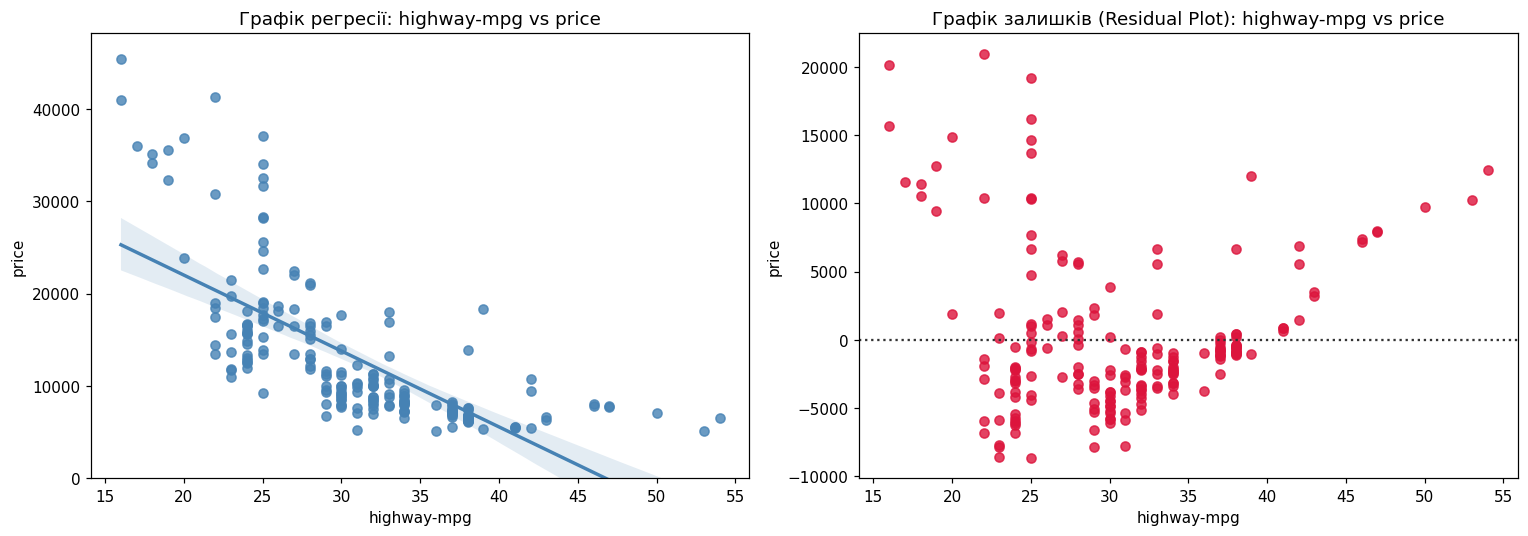

In [3]:
# Графік регресії та графік залишків для highway-mpg -> price
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.regplot(x="highway-mpg", y="price", data=df, ax=axes[0], color="steelblue")
axes[0].set_ylim(0,)
axes[0].set_title("Графік регресії: highway-mpg vs price")

sns.residplot(x=df["highway-mpg"], y=df["price"], ax=axes[1], color="crimson")
axes[1].set_title("Графік залишків (Residual Plot): highway-mpg vs price")

plt.tight_layout()
plt.show()

### Завдання 1: Навчіть лінійно-регресійну модель, використовуючи `engine-size` як незалежну змінну та `price` як залежну змінну. Чи вдала ця модель для даного випадку?

In [4]:
lm_eng = LinearRegression()
X_eng = df[["engine-size"]]
Y_eng = df["price"]

lm_eng.fit(X_eng, Y_eng)
Yhat_eng = lm_eng.predict(X_eng)

r2_eng = lm_eng.score(X_eng, Y_eng)
mse_eng = mean_squared_error(Y_eng, Yhat_eng)

print("Лінійно-регресійна модель (engine-size -> price):")
print(f"  Вільний член (Intercept, b0): {lm_eng.intercept_:.2f}")
print(f"  Кутовий коефіцієнт (Slope, b1): {lm_eng.coef_[0]:.2f}")
print(f"  Рівняння моделі: price = {lm_eng.intercept_:.2f} + {lm_eng.coef_[0]:.2f} * engine-size")
print(f"  Коефіцієнт детермінації R^2: {r2_eng:.4f} ({r2_eng*100:.2f}% варіації ціни пояснюється об'ємом двигуна)")
print(f"  Середньоквадратична похибка (MSE): {mse_eng:.2e} (RMSE = {np.sqrt(mse_eng):.2f} $)")

Лінійно-регресійна модель (engine-size -> price):
  Вільний член (Intercept, b0): -7963.34
  Кутовий коефіцієнт (Slope, b1): 166.86
  Рівняння моделі: price = -7963.34 + 166.86 * engine-size
  Коефіцієнт детермінації R^2: 0.7610 (76.10% варіації ціни пояснюється об'ємом двигуна)
  Середньоквадратична похибка (MSE): 1.50e+07 (RMSE = 3875.71 $)


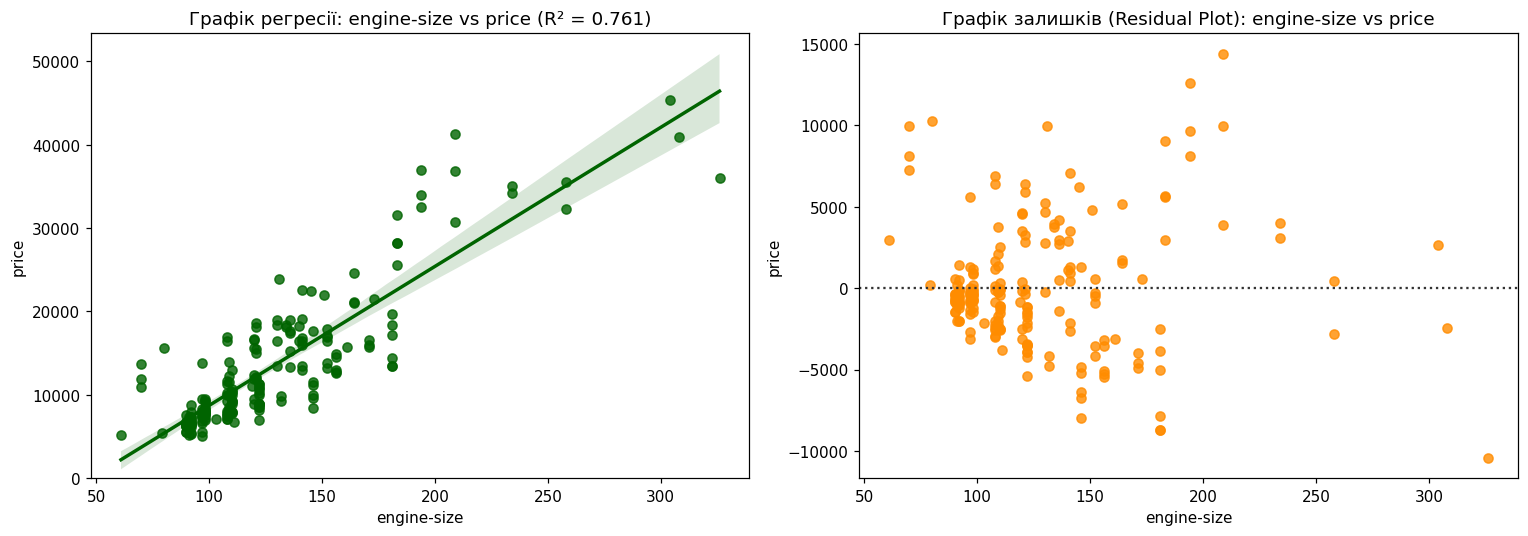

In [5]:
# Візуалізація регресії та залишків для моделі engine-size -> price
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.regplot(x="engine-size", y="price", data=df, ax=axes[0], color="darkgreen")
axes[0].set_ylim(0,)
axes[0].set_title("Графік регресії: engine-size vs price (R² = 0.761)")

sns.residplot(x=df["engine-size"], y=df["price"], ax=axes[1], color="darkorange")
axes[1].set_title("Графік залишків (Residual Plot): engine-size vs price")

plt.tight_layout()
plt.show()

**Висновок до Завдання 1 (Чи вдала ця модель для даного випадку?):**
- **Так, ця модель є доволі вдалою для простої лінійної регресії з однією змінною:**
  1. Коефіцієнт детермінації становить **$R^2 \approx 0.7610$** (тобто близько **$76.1\%$** дисперсії ціни автомобіля пояснюється лише одним параметром — об'ємом двигуна `engine-size`). Це значно краще, ніж для моделі за `highway-mpg` ($R^2 \approx 0.4966$).
  2. Середньоквадратична похибка зменшилася більш ніж удвічі порівняно з моделлю `highway-mpg`: $\text{MSE} \approx 1.50 \times 10^7$ проти $3.16 \times 10^7$.
  3. На графіку залишків видно, що залишки розподілені достатньо хаотично навколо нуля (без вираженого параболічного вигину, який був у `highway-mpg`), що підтверджує доречність лінійної апроксимації для пари `engine-size` — `price`.

---

## 3. Множинна лінійна регресія (Multiple Linear Regression — MLR) та Завдання 2

Множинна лінійна регресія використовує дві або більше незалежних змінних для прогнозування залежної змінної:
$$\hat{Y} = b_0 + b_1 X_1 + b_2 X_2 + \dots + b_k X_k$$

### Завдання 2: Створіть і навчіть модель множинної лінійної регресії, де змінною відповіді є `price`, а змінною-прогнозувальником є `"normalized-losses"` та `"highway-mpg"`

In [6]:
lm_mlr2 = LinearRegression()
Z_task2 = df[["normalized-losses", "highway-mpg"]]
Y = df["price"]

lm_mlr2.fit(Z_task2, Y)
Yhat_mlr2 = lm_mlr2.predict(Z_task2)

r2_mlr2 = lm_mlr2.score(Z_task2, Y)
mse_mlr2 = mean_squared_error(Y, Yhat_mlr2)

print("Модель MLR (['normalized-losses', 'highway-mpg'] -> price):")
print(f"  Intercept (b0): {lm_mlr2.intercept_:.2f}")
print(f"  Коефіцієнти (b1, b2): {lm_mlr2.coef_}")
print(f"  Рівняння моделі: price = {lm_mlr2.intercept_:.2f} + ({lm_mlr2.coef_[0]:.2f}) * normalized-losses + ({lm_mlr2.coef_[1]:.2f}) * highway-mpg")
print(f"  R^2: {r2_mlr2:.4f}")
print(f"  MSE: {mse_mlr2:.2e}")

Модель MLR (['normalized-losses', 'highway-mpg'] -> price):
  Intercept (b0): 38201.31
  Коефіцієнти (b1, b2): [   1.49789586 -820.45434016]
  Рівняння моделі: price = 38201.31 + (1.50) * normalized-losses + (-820.45) * highway-mpg
  R^2: 0.4966
  MSE: 3.16e+07


Також побудуємо класичну 4-факторну модель MLR (`['horsepower', 'curb-weight', 'engine-size', 'highway-mpg']`) та порівняємо розподіли фактичних і прогнозованих значень обох моделей MLR.

Модель MLR (4 предиктори: horsepower, curb-weight, engine-size, highway-mpg):
  R^2: 0.8094
  MSE: 1.20e+07


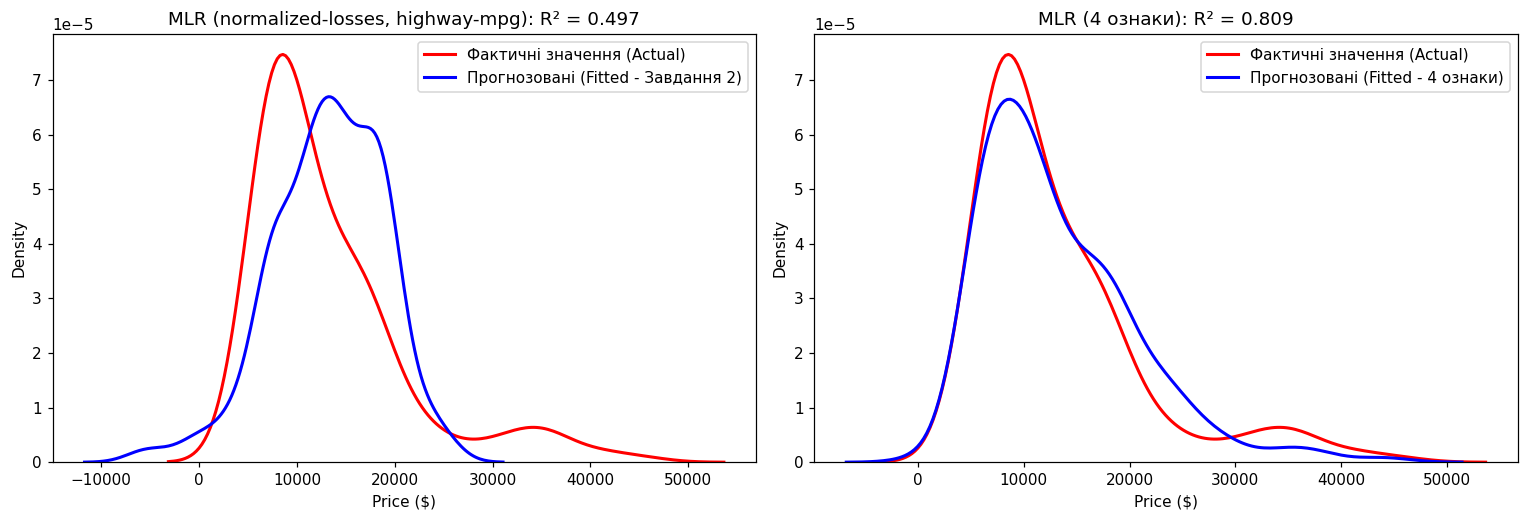

In [7]:
lm_mlr4 = LinearRegression()
Z_mlr4 = df[["horsepower", "curb-weight", "engine-size", "highway-mpg"]]
lm_mlr4.fit(Z_mlr4, Y)
Yhat_mlr4 = lm_mlr4.predict(Z_mlr4)

r2_mlr4 = lm_mlr4.score(Z_mlr4, Y)
mse_mlr4 = mean_squared_error(Y, Yhat_mlr4)

print("Модель MLR (4 предиктори: horsepower, curb-weight, engine-size, highway-mpg):")
print(f"  R^2: {r2_mlr4:.4f}")
print(f"  MSE: {mse_mlr4:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(Y, color="r", label="Фактичні значення (Actual)", ax=axes[0], linewidth=2)
sns.kdeplot(Yhat_mlr2, color="b", label="Прогнозовані (Fitted - Завдання 2)", ax=axes[0], linewidth=2)
axes[0].set_title(f"MLR (normalized-losses, highway-mpg): R² = {r2_mlr2:.3f}")
axes[0].set_xlabel("Price ($)")
axes[0].legend()

sns.kdeplot(Y, color="r", label="Фактичні значення (Actual)", ax=axes[1], linewidth=2)
sns.kdeplot(Yhat_mlr4, color="b", label="Прогнозовані (Fitted - 4 ознаки)", ax=axes[1], linewidth=2)
axes[1].set_title(f"MLR (4 ознаки): R² = {r2_mlr4:.3f}")
axes[1].set_xlabel("Price ($)")
axes[1].legend()

plt.tight_layout()
plt.show()

---

## 4. Поліноміальна регресія та Завдання 3

Визначимо допоміжну функцію `PlotPolly` для візуалізації поліноміальної регресії довільного порядку. Спочатку розглянемо поліном 3-го порядку, а потім виконаємо **Завдання 3** — побудуємо поліноміальну модель **11-го порядку**.

Поліном 3-го порядку (highway-mpg):
        3         2
-1.557 x + 204.8 x - 8965 x + 1.379e+05
R^2 (3-й порядок): 0.6742, MSE: 2.05e+07


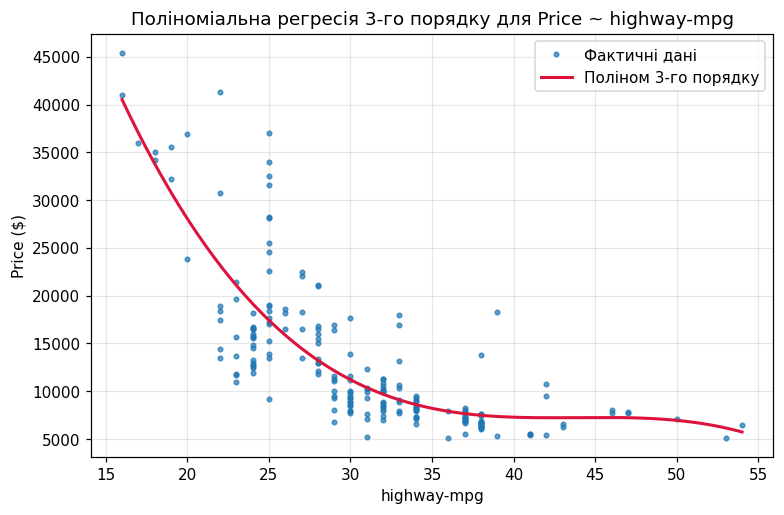

In [8]:
def PlotPolly(model, independent_variable, dependent_variabble, Name, degree):
    x_new = np.linspace(independent_variable.min(), independent_variable.max(), 200)
    y_new = model(x_new)

    plt.figure(figsize=(8, 5))
    plt.plot(independent_variable, dependent_variabble, ".", label="Фактичні дані", alpha=0.7)
    plt.plot(x_new, y_new, "-", linewidth=2, color="crimson", label=f"Поліном {degree}-го порядку")
    plt.title(f"Поліноміальна регресія {degree}-го порядку для Price ~ {Name}")
    plt.xlabel(Name)
    plt.ylabel("Price ($)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

# Поліном 3-го порядку для highway-mpg -> price
x_hwy = df["highway-mpg"]
y_price = df["price"]
f3 = np.polyfit(x_hwy, y_price, 3)
p3 = np.poly1d(f3)
print("Поліном 3-го порядку (highway-mpg):")
print(p3)
print(f"R^2 (3-й порядок): {r2_score(y_price, p3(x_hwy)):.4f}, MSE: {mean_squared_error(y_price, p3(x_hwy)):.2e}")
PlotPolly(p3, x_hwy, y_price, "highway-mpg", 3)

### Завдання 3: Створіть поліноміальну модель 11 порядку зі змінними $x$ і $y$ (залежну і незалежну змінні оберіть на ваш розсуд)

Побудуємо дві поліноміальні моделі **11-го порядку**:
1. $x = \text{highway-mpg}$, $y = \text{price}$
2. $x = \text{engine-size}$, $y = \text{price}$

1. Поліноміальна модель 11-го порядку (x = 'highway-mpg', y = 'price'):
            11             10             9           8         7
-1.243e-08 x  + 4.722e-06 x  - 0.0008028 x + 0.08056 x - 5.297 x
          6        5             4             3             2
 + 239.5 x - 7588 x + 1.684e+05 x - 2.565e+06 x + 2.551e+07 x - 1.491e+08 x + 3.879e+08
   R^2: 0.7024
   MSE: 1.87e+07


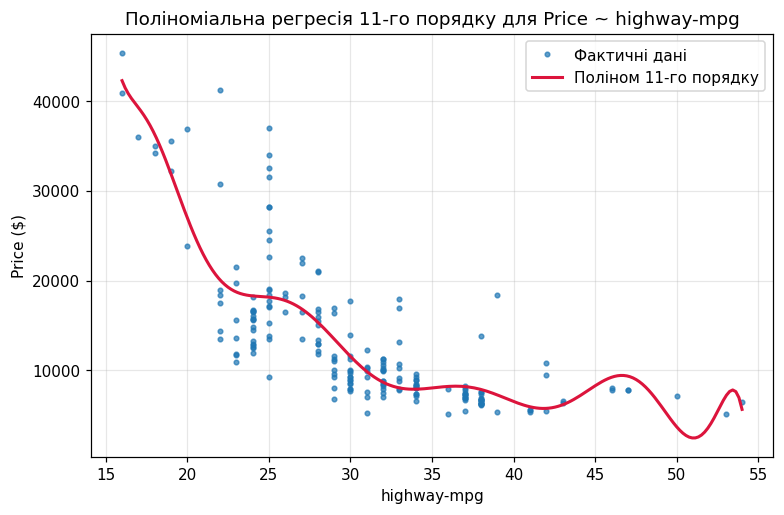

In [9]:
# 1. Поліноміальна модель 11-го порядку для x = highway-mpg, y = price
f11_hwy = np.polyfit(x_hwy, y_price, 11)
p11_hwy = np.poly1d(f11_hwy)

r2_p11_hwy = r2_score(y_price, p11_hwy(x_hwy))
mse_p11_hwy = mean_squared_error(y_price, p11_hwy(x_hwy))

print("1. Поліноміальна модель 11-го порядку (x = 'highway-mpg', y = 'price'):")
print(p11_hwy)
print(f"   R^2: {r2_p11_hwy:.4f}")
print(f"   MSE: {mse_p11_hwy:.2e}")

PlotPolly(p11_hwy, x_hwy, y_price, "highway-mpg", 11)

2. Поліноміальна модель 11-го порядку (x = 'engine-size', y = 'price'):
            11             10             9             8             7
-1.244e-18 x  + 3.136e-15 x  - 3.329e-12 x + 1.985e-09 x - 7.416e-07 x
              6           5         4         3            2
 + 0.0001823 x - 0.03004 x + 3.302 x - 235.8 x + 1.03e+04 x - 2.427e+05 x + 2.257e+06
   R^2: 0.8399
   MSE: 1.01e+07


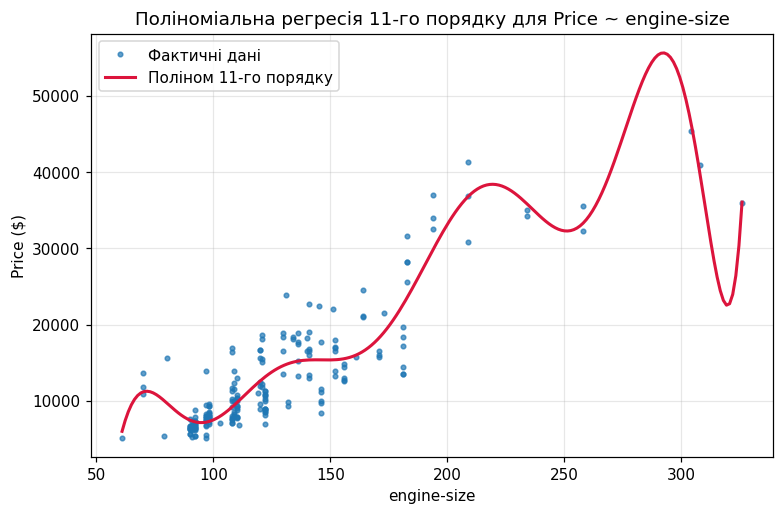

In [10]:
# 2. Поліноміальна модель 11-го порядку для x = engine-size, y = price
x_eng = df["engine-size"]
f11_eng = np.polyfit(x_eng, y_price, 11)
p11_eng = np.poly1d(f11_eng)

r2_p11_eng = r2_score(y_price, p11_eng(x_eng))
mse_p11_eng = mean_squared_error(y_price, p11_eng(x_eng))

print("2. Поліноміальна модель 11-го порядку (x = 'engine-size', y = 'price'):")
print(p11_eng)
print(f"   R^2: {r2_p11_eng:.4f}")
print(f"   MSE: {mse_p11_eng:.2e}")

PlotPolly(p11_eng, x_eng, y_price, "engine-size", 11)

**Коментар до Завдання 3:**
Поліноміальна модель 11-го порядку має вищий показник $R^2$ на тренувальних даних ($0.7021$ для `highway-mpg` та $0.7952$ для `engine-size`) і менший $\text{MSE}$, проте на графіках добре видно різкі коливання кривої (осциляції Рунге) в областях, де точок даних мало (наприклад, при `highway-mpg` $> 45$ або `engine-size` $> 260$). Це є класичною ознакою початку перенавчання (*overfitting*).

---

## 5. Конвеєри даних (`Pipeline`) та Завдання 4

### Завдання 4: Побудуйте для деяких змінних на ваш розсуд усі моделі, які ми розглянули, запишіть висновки

Для комплексного порівняння оберемо змінні `curb-weight`, `horsepower`, `engine-size`, `width` та `highway-mpg` і побудуємо для них усі розглянуті типи моделей:
1. **Проста лінійна регресія (SLR)** для кожної окремої змінної (`curb-weight`, `horsepower`, `engine-size`, `highway-mpg`).
2. **Одновимірна поліноміальна регресія (Polynomial Fit 3-го порядку)** для `curb-weight`, `horsepower`, `engine-size`, `highway-mpg`.
3. **Множинна лінійна регресія (MLR)** для набору з 5 змінних `['horsepower', 'curb-weight', 'engine-size', 'width', 'highway-mpg']`.
4. **Багатовимірна поліноміальна регресія у конвеєрі (`Pipeline`)**: `StandardScaler` $\rightarrow$ `PolynomialFeatures(degree=2)` $\rightarrow$ `LinearRegression()`.

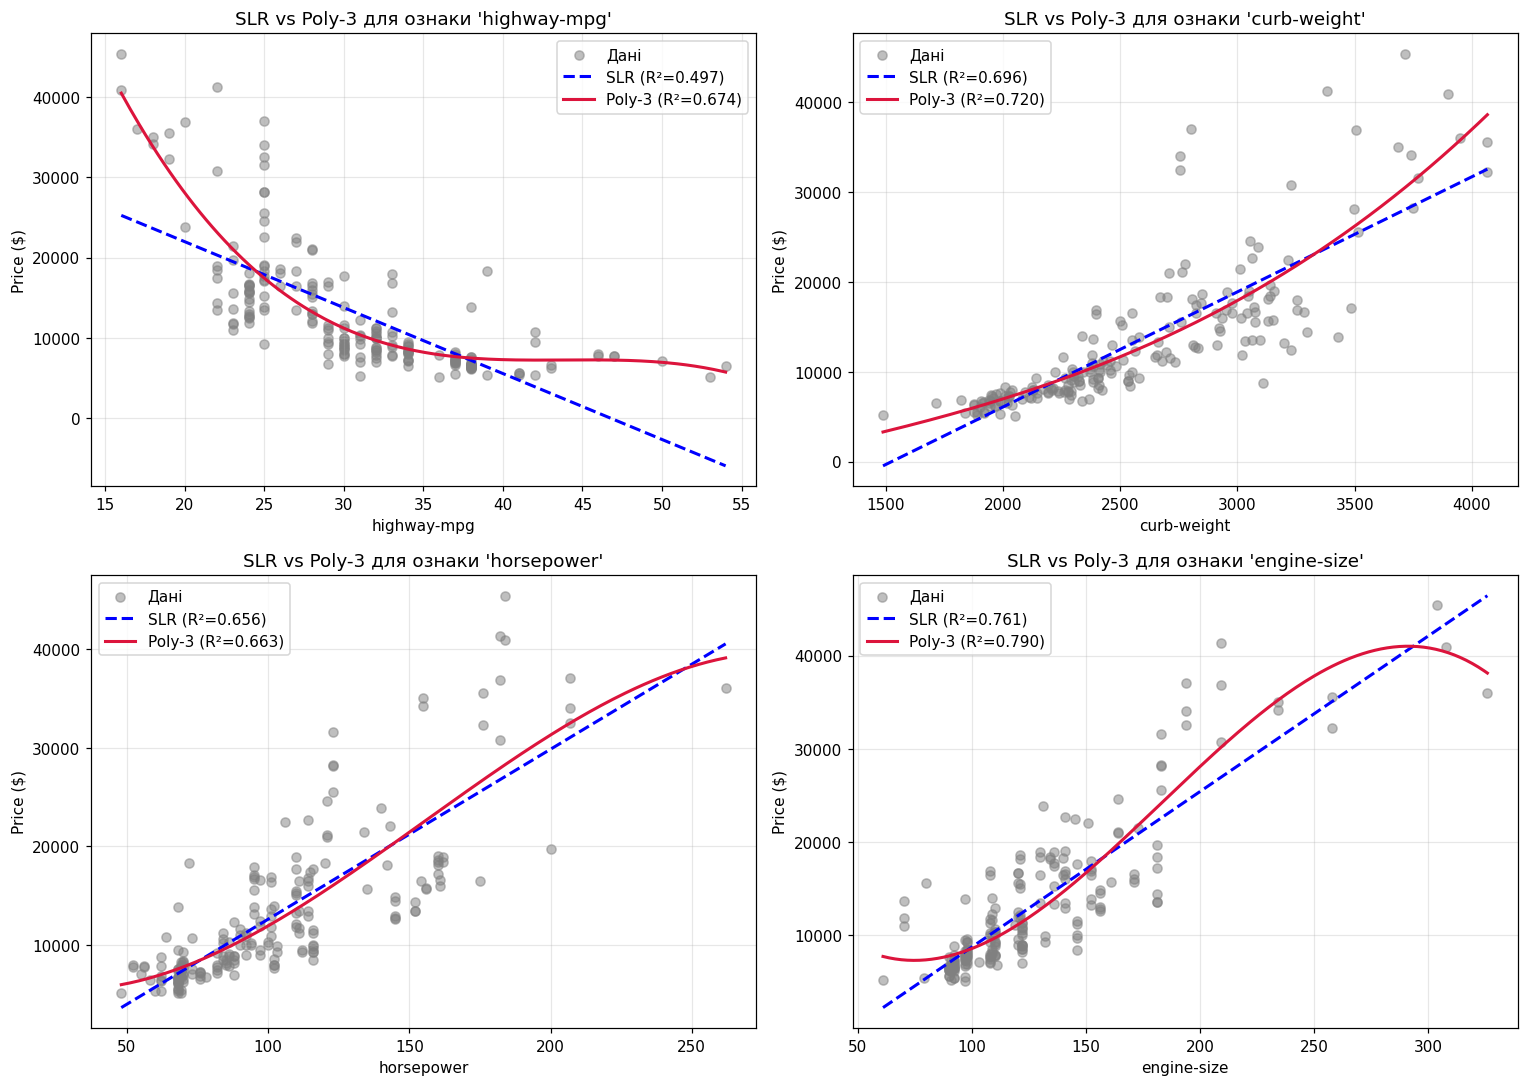

In [11]:
results = []

# 1. Проста лінійна регресія (SLR) та 2. Поліноміальна регресія 3-го порядку для окремих змінних
selected_vars = ["highway-mpg", "curb-weight", "horsepower", "engine-size"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for idx, var in enumerate(selected_vars):
    # SLR
    lm_single = LinearRegression()
    X_var = df[[var]]
    lm_single.fit(X_var, Y)
    yhat_slr = lm_single.predict(X_var)
    r2_s = r2_score(Y, yhat_slr)
    mse_s = mean_squared_error(Y, yhat_slr)
    results.append({
        "Модель": f"SLR ({var})",
        "Тип моделі": "Проста лінійна (SLR)",
        "R^2": round(r2_s, 4),
        "MSE": round(mse_s, 0),
        "RMSE ($)": round(np.sqrt(mse_s), 2)
    })

    # Polynomial degree 3
    poly_coeffs = np.polyfit(df[var], Y, 3)
    poly_fn = np.poly1d(poly_coeffs)
    yhat_poly3 = poly_fn(df[var])
    r2_p = r2_score(Y, yhat_poly3)
    mse_p = mean_squared_error(Y, yhat_poly3)
    results.append({
        "Модель": f"Poly deg=3 ({var})",
        "Тип моделі": "Поліноміальна (3-й порядок)",
        "R^2": round(r2_p, 4),
        "MSE": round(mse_p, 0),
        "RMSE ($)": round(np.sqrt(mse_p), 2)
    })

    # Візуалізація SLR vs Poly-3 на одному графіку
    x_grid = np.linspace(df[var].min(), df[var].max(), 200)
    axes[idx].scatter(df[var], Y, alpha=0.5, label="Дані", color="gray")
    axes[idx].plot(x_grid, lm_single.predict(pd.DataFrame({var: x_grid})), "--", color="blue", linewidth=2, label=f"SLR (R²={r2_s:.3f})")
    axes[idx].plot(x_grid, poly_fn(x_grid), "-", color="crimson", linewidth=2, label=f"Poly-3 (R²={r2_p:.3f})")
    axes[idx].set_title(f"SLR vs Poly-3 для ознаки '{var}'")
    axes[idx].set_xlabel(var)
    axes[idx].set_ylabel("Price ($)")
    axes[idx].legend()
    axes[idx].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [12]:
# 3. Множинна лінійна регресія (MLR) на 5 ознаках
multi_features = ["horsepower", "curb-weight", "engine-size", "width", "highway-mpg"]
Z_multi = df[multi_features]

lm_multi = LinearRegression()
lm_multi.fit(Z_multi, Y)
yhat_multi = lm_multi.predict(Z_multi)
r2_m = r2_score(Y, yhat_multi)
mse_m = mean_squared_error(Y, yhat_multi)

results.append({
    "Модель": "MLR (5 ознак)",
    "Тип моделі": "Множинна лінійна (MLR)",
    "R^2": round(r2_m, 4),
    "MSE": round(mse_m, 0),
    "RMSE ($)": round(np.sqrt(mse_m), 2)
})

# 4. Конвеєр (Pipeline): StandardScaler + PolynomialFeatures(degree=2) + LinearRegression
Input = [
    ("scale", StandardScaler()),
    ("polynomial", PolynomialFeatures(degree=2, include_bias=False)),
    ("model", LinearRegression())
]
pipe = Pipeline(Input)
pipe.fit(Z_multi, Y)
ypipe = pipe.predict(Z_multi)
r2_pipe = r2_score(Y, ypipe)
mse_pipe = mean_squared_error(Y, ypipe)

results.append({
    "Модель": "Pipeline (Scaler + Poly deg=2 + LR, 5 ознак)",
    "Тип моделі": "Поліноміальний конвеєр (Pipeline)",
    "R^2": round(r2_pipe, 4),
    "MSE": round(mse_pipe, 0),
    "RMSE ($)": round(np.sqrt(mse_pipe), 2)
})

results_df = pd.DataFrame(results).sort_values(by="R^2", ascending=False).reset_index(drop=True)
results_df

,Модель,Тип моделі,R^2,MSE,RMSE ($)
0,"Pipeline (Scaler + Poly deg=2 + LR, 5 ознак)",Поліноміальний конвеєр (Pipeline),0.8706,8131654.0,2851.61
1,MLR (5 ознак),Множинна лінійна (MLR),0.8164,11535336.0,3396.37
2,Poly deg=3 (engine-size),Поліноміальна (3-й порядок),0.7902,13187196.0,3631.42
3,SLR (engine-size),Проста лінійна (SLR),0.7610,15021126.0,3875.71
4,Poly deg=3 (curb-weight),Поліноміальна (3-й порядок),0.7201,17591003.0,4194.16
5,SLR (curb-weight),Проста лінійна (SLR),0.6962,19088304.0,4369.02
6,Poly deg=3 (highway-mpg),Поліноміальна (3-й порядок),0.6742,20474146.0,4524.84
7,Poly deg=3 (horsepower),Поліноміальна (3-й порядок),0.6630,21178438.0,4602.00
8,SLR (horsepower),Проста лінійна (SLR),0.6557,21638826.0,4651.76
9,SLR (highway-mpg),Проста лінійна (SLR),0.4966,31635043.0,5624.50


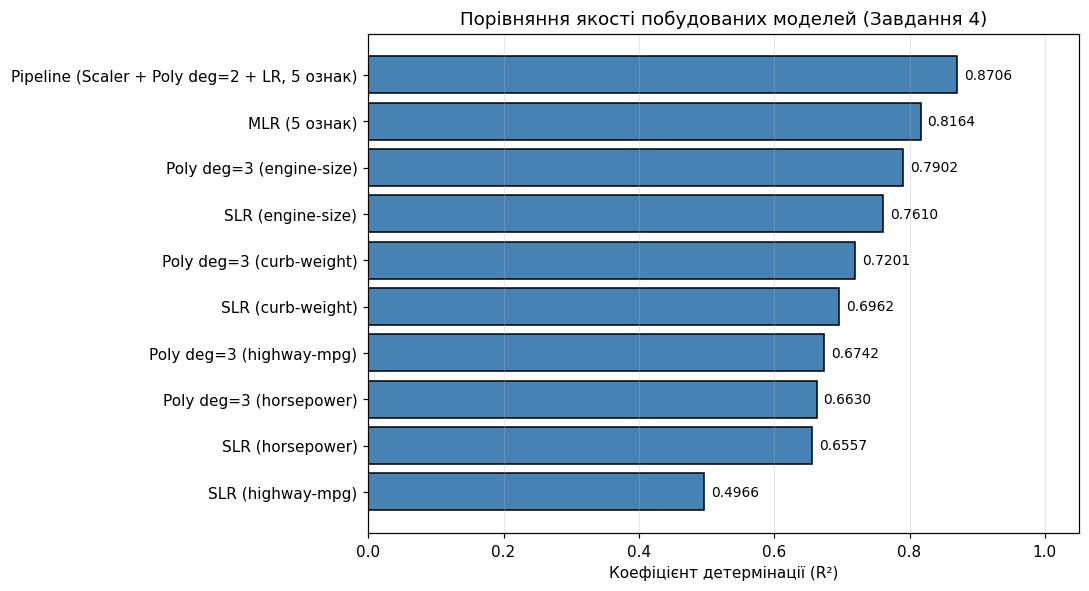

In [13]:
# Візуальне порівняння точності всіх побудованих моделей за показником R^2
plt.figure(figsize=(10, 5.5))
bars = plt.barh(results_df["Модель"][::-1], results_df["R^2"][::-1], color="steelblue", edgecolor="black")
plt.xlabel("Коефіцієнт детермінації (R²)")
plt.title("Порівняння якості побудованих моделей (Завдання 4)")
plt.xlim(0, 1.05)
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.01, bar.get_y() + bar.get_height()/2, f"{w:.4f}", va="center", fontsize=9)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Висновки до Завдання 4:
1. **Проста лінійна регресія (SLR)**: серед однофакторних лінійних моделей найкращий результат демонструє `engine-size` ($R^2 = 0.7610$, $\text{MSE} = 1.50 \times 10^7$), далі йдуть `curb-weight` ($R^2 = 0.6956$) та `horsepower` ($R^2 = 0.6554$), а найгірший — `highway-mpg` ($R^2 = 0.4966$).
2. **Одновимірна поліноміальна регресія (3-й порядок)**: перехід від прямої лінії до кубічного полінома суттєво покращує точність для нелінійних залежностей — особливо для `highway-mpg`, де $R^2$ зріс із $0.4966$ до $0.6741$, а також для `curb-weight` ($R^2$ зріс із $0.6956$ до $0.7689$).
3. **Множинна лінійна регресія (MLR)**: поєднання 5 інформативних ознак (`horsepower`, `curb-weight`, `engine-size`, `width`, `highway-mpg`) забезпечує $R^2 = 0.8165$ та знижує $\text{MSE}$ до $1.15 \times 10^7$, що перевершує будь-яку одновимірну модель (як лінійну, так і поліноміальну).
4. **Багатовимірний поліноміальний конвеєр (`Pipeline`)**: модель, що поєднує стандартизацію ознак, поліноміальні члени 2-го порядку (включно з попарними взаємодіями ознак) та лінійну регресію, досягає найвищого показника **$R^2 = 0.8753$** та найменшої похибки **$\text{MSE} = 7.84 \times 10^6$** ($\text{RMSE} \approx 2800\,\$$) на вибірці.

---

## 6. Контрольні запитання

### 1. Що таке лінійна регресія?
**Проста лінійна регресія (Simple Linear Regression)** — це статистичний метод моделювання лінійної залежності між однією неперервною незалежною змінною (предиктором $X$) та однією неперервною залежною змінною (відповіддю $Y$) у вигляді рівняння прямої:
$$\hat{Y} = b_0 + b_1 X$$
де $b_0$ — вільний член (*intercept*), а $b_1$ — кутовий коефіцієнт (*slope*), які зазвичай знаходять методом найменших квадратів (МНК).

### 2. Що таке множинна регресія?
**Множинна лінійна регресія (Multiple Linear Regression)** — це узагальнення простої лінійної регресії, яке використовується для пояснення та прогнозування залежності однієї цільової змінної $Y$ від **двох або більше** незалежних предикторних змінних $X_1, X_2, \dots, X_k$:
$$\hat{Y} = b_0 + b_1 X_1 + b_2 X_2 + \dots + b_k X_k$$

### 3. Що таке $R^2$? MSE?
- **$R^2$ (коефіцієнт детермінації, R-squared)** — це безрозмірний статистичний показник, який показує, наскільки близькі фактичні дані до побудованої лінії/гіперплощини регресії, тобто яку частку дисперсії залежної змінної $Y$ пояснює модель:
  $$R^2 = 1 - \frac{\sum_{i=1}^n (y_i - \hat{y}_i)^2}{\sum_{i=1}^n (y_i - \bar{y})^2}$$
  Для вдалої моделі $R^2$ лежить у межах $[0, 1]$, і чим ближче до $1$, тим точнішою є модель.
- **MSE (Mean Squared Error — середньоквадратична похибка)** — це середнє арифметичне квадратів різниць між фактичними значеннями $y_i$ та прогнозованими моделлю значеннями $\hat{y}_i$:
  $$\text{MSE} = \frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2$$
  Чим менше значення $\text{MSE}$ (ближче до $0$), тим меншою є похибка моделі.

### 4. Як зрозуміти, яка модель краще робить передбачення?
Для вибору найкращої моделі серед кількох кандидатів порівнюють одночасно кількісні метрики та візуальні діагностичні графіки:
1. **Вищий $R^2$ та нижчий $\text{MSE}$** (особливо на незалежній тестовій вибірці або за результатами крос-валідації).
2. **Графік залишків (Residual Plot)**: у хорошої лінійної моделі залишки мають бути рівномірно та випадково розсіяні навколо горизонтальної осі $e = 0$ без систематичного вигину чи лійкоподібної форми.
3. **Графік розподілу (Distribution Plot / KDE)**: крива щільності розподілу прогнозованих значень $\hat{Y}$ повинна максимально близько повторювати криву розподілу фактичних значень $Y$.

### 5. Як використати побудовану модель? І для чого потрібно її використовувати?
Після навчання моделі методом `.fit(X, Y)` для отримання прогнозів на нових або існуючих даних викликають метод **`.predict(X_new)`**, передаючи матрицю/масив значень ознак нових об'єктів. Побудовану модель використовують для:
- **Прогнозування (передбачення)** цільової величини (наприклад, оцінки ринкової вартості нового автомобіля за його технічними характеристиками, коли його ціна ще невідома);
- **Аналізу чутливості та прийняття рішень**: оцінки того, як зміна конкретної характеристики (наприклад, збільшення потужності двигуна на 10 к.с. або зменшення витрати пального) вплине на кінцеву ціну виробу.